# pPXF vs kinextract -- head-to-head comparison on a reflected dartboard-binned cube

**Status: temporary testing notebook**, not part of the polished `examples/notebooks/`
suite. Purpose: run both pPXF (parametric, Gauss-Hermite moments) and
`kinextract` (non-parametric spline LOSVD) on the *same* dartboard-binned
cube and compare spectral fits, recovered LOSVD shapes, and 2D moment maps.

Set `DATA_MODE` below to switch between the synthetic cube built by
`04_template_calibration.ipynb`'s own `build_mock_cube` and the real NGC 5102
MUSE cube downloaded to `examples/notebooks/muse_download/`.

Both methods are run at `moments=4` / non-parametric-equivalent settings on
**identical dartboard bins** (Section 3 -- log-radial, reflected
equal-sin(theta), no combination across the major/minor axis) and (for a
given `DATA_MODE`) the **same template library**, so any systematic
difference in the recovered maps reflects the fitting method, not different
inputs.

In [1]:
from __future__ import annotations

import pickle
import time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt

from ppxf.ppxf import ppxf
import ppxf.ppxf_util as putil

from kinextract import (
    FitConfig, build_mock_cube, load_muse_cube, load_emiles_templates,
    build_template_stack, compute_losvd_moments, gauss_hermite_model,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset

# ignore warnings about all-NaN slices when computing the white-light image
import warnings

np.set_printoptions(legacy='1.25')

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)


## 1. Load the cube -- swap `DATA_MODE` to switch synthetic <-> real

In [2]:
DATA_MODE = "real"   # "synthetic" | "real"
USE_CACHE = False     # load cached kinextract/pPXF fit results if available, else compute + save

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
REAL_CUBE_PATH = "../../examples/notebooks/muse_download/ADP.2017-03-22T15:25:58.757.fits"
TEMPLATE_SUBSET_PATH = "../../examples/data/muse/ngc5102_template_subset.npz"

WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0   # CaII triplet fit window, rest frame
TARGET_SN = 800.0

if DATA_MODE == "synthetic":
    cube = build_mock_cube(EMILES_GRID, ny=50, nx=50, seed=0)
    z = 0.0
    # the exact 3 templates + weights the mock was built from -- fitting with
    # these (instead of the full 636-template grid) keeps runtime sane and
    # matches what this cube's truth actually is.
    select = cube.truth["template_select"]
    templates, template_wave, template_names, template_ages, template_metals = (
        load_emiles_templates(EMILES_GRID, select=select)
    )
    print(f"synthetic cube truth: V={cube.truth['true_v']}, sigma={cube.truth['true_sigma']}, "
          f"h3={cube.truth['true_h3']}, h4={cube.truth['true_h4']}, "
          f"template_select={select}")

elif DATA_MODE == "real":
    cube = load_muse_cube(REAL_CUBE_PATH)
    z = 468.0 / 299792.458   # NGC 5102 systemic velocity ~468 km/s (NED) -- no redshift header in this FITS file
    # the reduced, validated template subset from 04_template_calibration.ipynb
    # (full 636-template grid is both far slower and, per that notebook's own
    # findings, less reliable for real-data weight recovery than a curated subset).
    subset = load_template_subset(TEMPLATE_SUBSET_PATH)
    union_idx = subset["union_selected"]
    select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
    templates, template_wave, template_names, template_ages, template_metals = (
        load_emiles_templates(EMILES_GRID, select=select)
    )
    print(f"real cube: {len(templates)} templates from the saved calibration subset")

else:
    raise ValueError(f"unknown DATA_MODE: {DATA_MODE!r}")

ny, nx = cube.shape
print(f"cube shape: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={cube.pixel_scale}\", "
      f"{len(templates)} templates")


real cube: 9 templates from the saved calibration subset
cube shape: (3681, 317, 318) (n_wave, ny, nx), pixel_scale=0.20000000000000015", 9 templates


## 2. Restrict to the fit window and build per-spaxel signal/noise maps

Same CaII-triplet rest-frame window used throughout this package's real-data
notebooks. For the synthetic cube `z=0` and `cube.wave` is already this exact
window, so the mask below is a no-op there and only does real work in
`DATA_MODE="real"`.

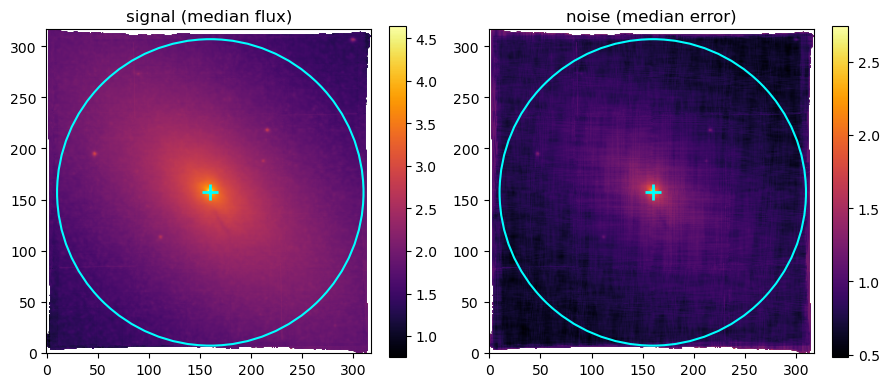

70661 / 100806 spaxels usable within R <= 30 arcsec, 321 wavelength pixels in the fit window


In [3]:
wave_rest = cube.wave / (1.0 + z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_fit = wave_rest[in_window]
flux_cube = cube.flux[in_window]     # (n_pix, ny, nx)
error_cube = cube.error[in_window]

yy, xx = np.indices((ny, nx))
x_arcsec = (xx - (nx - 1) / 2.0) * cube.pixel_scale
y_arcsec = (yy - (ny - 1) / 2.0) * cube.pixel_scale

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    signal_map = np.nanmedian(flux_cube, axis=0)
    noise_map = np.nanmedian(error_cube, axis=0)

good0 = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)

brightest_spaxel_y, brightest_spaxel_x = np.unravel_index(
    np.nanargmax(np.where(good0, signal_map, np.nan)), signal_map.shape
)

RMAX_ARCSEC = 30
r_arcsec = np.hypot(x_arcsec - x_arcsec[brightest_spaxel_y, brightest_spaxel_x],
                    y_arcsec - y_arcsec[brightest_spaxel_y, brightest_spaxel_x])

good = good0 & (r_arcsec <= RMAX_ARCSEC)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
im0 = axes[0].imshow(np.where(signal_map > 0, np.log10(signal_map), np.nan), origin='lower', cmap='inferno')
axes[0].set_title('signal (median flux)')
im1 = axes[1].imshow(np.where(noise_map > 0, np.log10(noise_map), np.nan), origin='lower', cmap='inferno')
axes[1].set_title('noise (median error)')

for ax in axes:
    ax.plot(brightest_spaxel_x, brightest_spaxel_y, '+', color='cyan', ms=12, mew=2)
    ax.add_patch(plt.Circle((brightest_spaxel_x, brightest_spaxel_y),
                            RMAX_ARCSEC / cube.pixel_scale,
                            edgecolor='cyan', facecolor='none', lw=1.5))

plt.colorbar(im0, ax=axes[0], fraction=0.046)
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

print(f"{good.sum()} / {good.size} spaxels usable within R <= {RMAX_ARCSEC} arcsec, "
      f"{len(wave_fit)} wavelength pixels in the fit window")

## 3. Reflected sin(theta) dartboard binning (sco_framework-style, no axis combination)

Replaces the earlier Voronoi (target-S/N) scheme with a **fixed geometric
dartboard**: radial annuli log-spaced in `r`, crossed with angular sectors
equally spaced in `sin(theta)` (not `theta` itself) measured from the
**kinematic major axis** -- so sectors are narrowest near the major axis
and widest near the minor axis, exactly like the `sco_framework` pipeline's
own `bin_r.out`/`bin_v.out` (`binspectra`/`plotbin3`) convention. Verified
directly against `sco_framework_updated/sco_workdir_example/analysis/N5102/
kinematics/muse/spectral_binning/bin_v.out`: its 5 angular edges per
quadrant (11.54, 23.58, 36.87, 53.13, 90.00 deg) are exactly
`arcsin([0.2,0.4,0.6,0.8,1.0])` -- reproduced below by `N_THETA_PER_QUADRANT`.
`REFERENCE_R_EDGES_ARCSEC` is that same file's own radial edges (`rup`
column), rescaled to the cube's FOV and truncated at `RMAX_ARCSEC` (set in
Section 2 -- a smaller `RMAX_ARCSEC` gives fewer radial bins and a faster
fit loop, not a rescaled log spacing).

**The one deliberate change from the legacy scheme**: `plot_dartboard` in
`IMBH_Project/.../talk_figures_n5102.ipynb` builds this exact 4-quadrant
wedge pattern but then *combines* data across pairs of those wedges (the
standard assumed-symmetry trick real dynamical-modeling pipelines use to
halve the number of independent spectra needed). **Here every one of the 4
reflected wedges is its own independent bin**, built only from the spaxels
that actually fall inside it -- no combination across the major or minor
axis, so an asymmetric feature (real or a fitting artifact) shows up as an
asymmetry in the maps below instead of being averaged away.

**The binning implementation itself now lives in `dartboard_pa.py`** (next
to this notebook), not inline here -- `build_reflected_sin_theta_edges`,
`assign_spaxels_to_bins_pa` (a PA-aware adaptation of the package's own
`kinextract.binning.assign_spaxels_to_bins` -- that function has no
position-angle parameter, by design, see its module docstring), and the
`build_pa_dartboard` convenience wrapper that does the rest (centering,
bin-id renumbering, `x_gen`/`y_gen`/`bin_number`/`bin_sn`) in one call.

`PA_DEG` for the real cube is 45.77 deg (+90 deg, see below), the kinematic
PA this exact target's own finalized analysis uses
(`IMBH_Project/.../talk_figures_n5102.ipynb`, cell defining `rotation_angle`)
-- the extra +90 was added after checking the radial/theta-index diagnostic
plot below against the real galaxy image; adjust it further if the overlaid
major/minor axis lines don't look right for your own PA convention. For the
synthetic cube (spatially constant kinematics, no real position angle to
speak of) it's an arbitrary 0.0 -- only the bin *shapes* matter there, not
their absolute orientation.

239 dartboard bins (18 radial x 20 angular, PA=135.8 deg, RMAX=30.0", center pixel=(160, 157))
good spaxels after binning = 70661 / 100806
estimated kinextract runtime below: ~32 min for 239 bins (~8s/bin after JIT warmup)


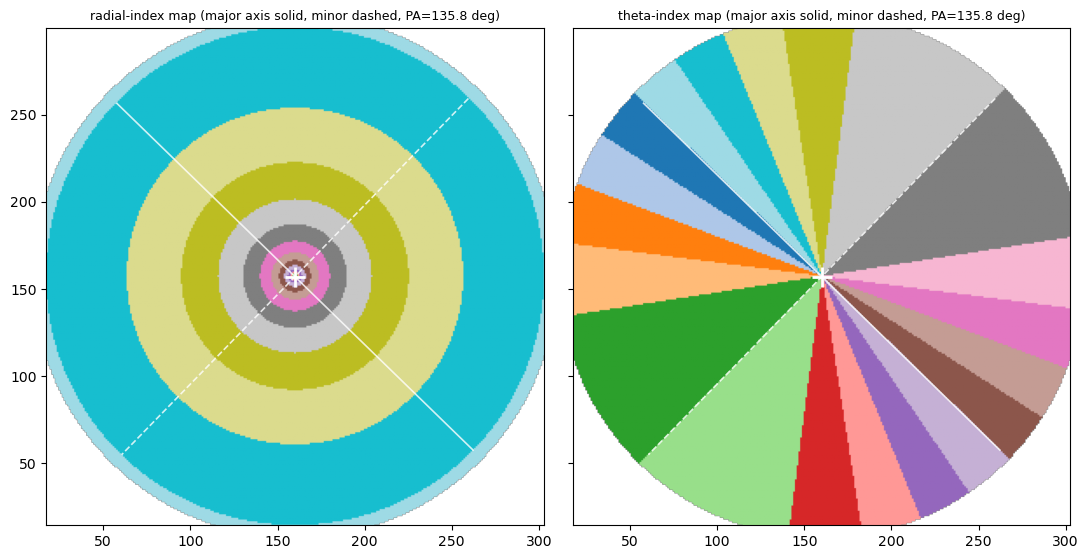

In [4]:
from dartboard_pa import build_pa_dartboard

# sco_framework's own N5102 MUSE radial bin edges (bin_r.out's "rup" column, arcsec) --
# see: sco_framework_updated/sco_workdir_example/analysis/N5102/kinematics/muse/
# spectral_binning/bin_r.out -- used as a GUIDE for bin sizes/count (build_radial_edges
# rescales to the cube's own FOV, then truncates at RMAX_ARCSEC).
REFERENCE_R_EDGES_ARCSEC = np.array([
    0.021, 0.048, 0.088, 0.147, 0.235, 0.365, 0.557, 0.841, 1.261, 1.883,
    2.801, 4.160, 6.171, 9.143, 13.540, 20.044, 29.662, 43.888,
])
N_THETA_PER_QUADRANT = 5   # 5 matches bin_v.out exactly (arcsin([0.2,0.4,0.6,0.8,1.0]))
PA_DEG = 45.77 + 90 if DATA_MODE == "real" else 0.0   # kinematic major-axis PA; see markdown above

result = build_pa_dartboard(
    good, signal_map, noise_map, x_arcsec, y_arcsec, cube.pixel_scale,
    pa_deg=PA_DEG, rmax_arcsec=RMAX_ARCSEC, reference_r_edges_arcsec=REFERENCE_R_EDGES_ARCSEC,
    n_theta_per_quadrant=N_THETA_PER_QUADRANT,
)
bin_map, nbins, bin_number = result.bin_map, result.nbins, result.bin_number
x_gen, y_gen, bin_sn = result.x_gen, result.y_gen, result.bin_sn
good = result.good   # narrowed to spaxels that actually landed in a populated bin
center_pix = result.center_pix

print(f"{nbins} dartboard bins ({result.bins.n_radial} radial x {result.bins.n_angular} angular, "
      f"PA={PA_DEG:.1f} deg, RMAX={RMAX_ARCSEC:.1f}\", center pixel={center_pix})")
print(f"good spaxels after binning = {good.sum()} / {good.size}")
est_minutes = nbins * 8 / 60.0
print(f"estimated kinextract runtime below: ~{est_minutes:.0f} min for {nbins} bins (~8s/bin after JIT warmup)")
if nbins > 300:
    print(f"WARNING: {nbins} bins is a lot for a per-bin two-stage fit -- consider a smaller RMAX_ARCSEC "
          f"or fewer N_THETA_PER_QUADRANT before running the fit cells below.")

# Diagnostic: radial-index and theta-index maps, with the PA-aligned major/minor axes
# overlaid, so a wrong PA_DEG or a badly-placed center is visible immediately.
pa_rad = np.radians(PA_DEG)
axis_len = 0.9 * min(nx, ny) / 2
fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, index_map, label in zip(axes, [result.r_index_map, result.theta_index_map], ["radial", "theta"]):
    ax.imshow(index_map, origin='lower', cmap='tab20')
    ax.plot(center_pix[0], center_pix[1], '+', color='white', ms=14, mew=2)
    for ang, style in [(pa_rad, '-'), (pa_rad + np.pi / 2, '--')]:
        ax.plot([center_pix[0] - axis_len * np.cos(ang), center_pix[0] + axis_len * np.cos(ang)],
                [center_pix[1] - axis_len * np.sin(ang), center_pix[1] + axis_len * np.sin(ang)],
                style, color='white', lw=1.2, alpha=0.8)
    ax.set_title(f"{label}-index map (major axis solid, minor dashed, PA={PA_DEG:.1f} deg)", fontsize=9)
    ax.set_ylim(center_pix[1] - axis_len, center_pix[1] + axis_len)
    ax.set_xlim(center_pix[0] - axis_len, center_pix[0] + axis_len)
plt.tight_layout(); plt.show()


## 4. Build one combined spectrum per dartboard bin

In [5]:
def build_bin_spectra(flux_cube, error_cube, bin_map, nbins):
    """Mean flux and propagated variance-of-the-mean per bin."""
    n_pix = flux_cube.shape[0]
    spectra = np.full((n_pix, nbins), np.nan)
    variance = np.full((n_pix, nbins), np.nan)
    for j in range(nbins):
        mask = bin_map == j
        n = int(mask.sum())
        if n == 0:
            continue
        spectra[:, j] = np.nanmean(flux_cube[:, mask], axis=1)
        variance[:, j] = np.nansum(error_cube[:, mask] ** 2, axis=1) / n ** 2
    return spectra, variance


bin_spectra, bin_variance = build_bin_spectra(flux_cube, error_cube, bin_map, nbins)
bin_errors = np.sqrt(np.clip(bin_variance, 1e-12, None))
print(f"built {nbins} bin spectra, {bin_spectra.shape[0]} pixels each")


built 239 bin spectra, 321 pixels each


## 5. Fit every bin with kinextract

Two-stage fit (wide default grid, then a centered `V +/- 7*sigma` refit),
the same convention used in `05_real_data_muse.ipynb`.

In [23]:
NSIG = 7

# Cache key covers everything that changes what gets fit: which cube/mode, the
# binning geometry (PA/RMAX/theta resolution), and the resulting bin count as a
# cheap fingerprint that the bin geometry actually changed.
CACHE_TAG = f"{DATA_MODE}_pa{PA_DEG:.1f}_rmax{RMAX_ARCSEC:.1f}_nt{N_THETA_PER_QUADRANT}_nb{nbins}"
kin_cache_path = CACHE_DIR / f"kin_{CACHE_TAG}.pkl"


def fit_bin_kinextract(wave_fit, flux, errors, nsig=NSIG):
    y_w = flux / errors

    # # Stage 1: generous, fixed default grid -- rough estimate only.
    # cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
    # v_grid_wide = cfg_wide.build_velocity_grid()
    # A_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
    # A_w_wide = A_wide / errors[None, :, None]
    # result_wide = fit_losvd(A_w_wide, y_w, cfg_wide)
    # moments_wide = compute_losvd_moments(v_grid_wide, result_wide['b'], fit_h3h4=False)

    # Stage 2: refit on a properly centered V +/- nsig*sigma grid.
    # cfg = FitConfig(vmin=moments_wide['vherm'] - nsig * moments_wide['sherm'],
    #                  vmax=moments_wide['vherm'] + nsig * moments_wide['sherm'])

    cfg = FitConfig(vmin=-400.0, 
                    vmax=400.0, 
                    continuum_knots=4, 
                    lam_selection='fixed',
                    penalty_order=2 
                    )

    v_grid = cfg.build_velocity_grid()
    A = build_template_stack(wave_fit, template_wave, templates, v_grid)
    A_w = A / errors[None, :, None]
    result = fit_losvd(A_w, y_w, cfg, wave_fit=wave_fit)
    moments = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)

    A_eff_w = np.tensordot(result['w'], A_w, axes=([0], [0]))
    model_w = A_eff_w @ result['b']
    model = model_w * errors
    chi2_red = float(np.sum((model_w - y_w) ** 2)) / len(wave_fit)

    return dict(v_grid=v_grid, b=result['b'], moments=moments, model=model, chi2_red=chi2_red)


if USE_CACHE and kin_cache_path.exists():
    with open(kin_cache_path, "rb") as f:
        kin_results = pickle.load(f)
    print(f"loaded {len(kin_results)} kinextract results from cache: {kin_cache_path.name}")
else:
    t0 = time.time()
    kin_results = []
    for j in range(nbins):
        kin_results.append(fit_bin_kinextract(wave_fit, bin_spectra[:, j], bin_errors[:, j]))
        if (j + 1) % 10 == 0 or j == nbins - 1:
            print(f"  kinextract: {j + 1}/{nbins} bins fit ({time.time() - t0:.0f}s elapsed)")
    print(f"kinextract: done, {time.time() - t0:.0f}s total")
    with open(kin_cache_path, "wb") as f:
        pickle.dump(kin_results, f)
    print(f"saved kinextract results to cache: {kin_cache_path.name}")


  kinextract: 10/239 bins fit (11s elapsed)
  kinextract: 20/239 bins fit (21s elapsed)
  kinextract: 30/239 bins fit (29s elapsed)
  kinextract: 40/239 bins fit (37s elapsed)
  kinextract: 50/239 bins fit (48s elapsed)
  kinextract: 60/239 bins fit (58s elapsed)
  kinextract: 70/239 bins fit (70s elapsed)
  kinextract: 80/239 bins fit (87s elapsed)
  kinextract: 90/239 bins fit (100s elapsed)
  kinextract: 100/239 bins fit (114s elapsed)
  kinextract: 110/239 bins fit (126s elapsed)
  kinextract: 120/239 bins fit (135s elapsed)
  kinextract: 130/239 bins fit (144s elapsed)
  kinextract: 140/239 bins fit (149s elapsed)
  kinextract: 150/239 bins fit (158s elapsed)
  kinextract: 160/239 bins fit (164s elapsed)
  kinextract: 170/239 bins fit (172s elapsed)
  kinextract: 180/239 bins fit (178s elapsed)
  kinextract: 190/239 bins fit (184s elapsed)
  kinextract: 200/239 bins fit (189s elapsed)
  kinextract: 210/239 bins fit (194s elapsed)
  kinextract: 220/239 bins fit (197s elapsed)
  kin

## 6. Fit every bin with pPXF (4 moments)

pPXF needs log-rebinned (constant velocity-step) spectra and templates, unlike
`kinextract` which works directly on the linear wavelength grid. Both
methods otherwise see the same per-bin data and the same template library
(log-rebinned once here for pPXF, used directly above for `kinextract`).

This is a plain single-pass `moments=4` fit (no iterative sigma-clipping /
outlier-masking stage as in the `pPXF_N5102.ipynb` reference notebook) --
a deliberate simplification for this temporary comparison, not a claim that
it is the most careful possible pPXF setup.

In [24]:
c_kms = 299792.458
velscale = c_kms * np.min(np.diff(np.log(wave_fit)))
lam_range_gal = [wave_fit.min(), wave_fit.max()]

bin_spectra_log, ln_lam_gal, velscale = putil.log_rebin(lam_range_gal, bin_spectra, velscale=velscale)
bin_variance_log, _, _ = putil.log_rebin(lam_range_gal, bin_variance, velscale=velscale)
bin_variance_log = np.clip(bin_variance_log, 1e-12, None)
bin_noise_log = np.sqrt(bin_variance_log)
lam_gal_log = np.exp(ln_lam_gal)

templates_lin = np.column_stack(templates)
lam_range_temp = [template_wave.min(), template_wave.max()]
templates_log, ln_lam_temp, _ = putil.log_rebin(lam_range_temp, templates_lin, velscale=velscale)
lam_temp = np.exp(ln_lam_temp)

ppxf_cache_path = CACHE_DIR / f"ppxf_{CACHE_TAG}.pkl"


def fit_bin_ppxf(j, moments=4, degree=6, mdegree=2):
    galaxy = bin_spectra_log[:, j]
    noise = bin_noise_log[:, j]
    start = [0.0, 100.0]
    return ppxf(templates_log, galaxy, noise, velscale, start,
                moments=moments, degree=degree, mdegree=mdegree,
                lam=lam_gal_log, lam_temp=lam_temp, quiet=True)


# Only sol/bestfit/chi2 are used anywhere downstream -- cache (and use, even on a
# fresh run) a small SimpleNamespace instead of the full ppxf object, which also
# carries large internal arrays and isn't guaranteed picklable/stable across
# ppxf versions.
def _slim(pp):
    return SimpleNamespace(sol=np.asarray(pp.sol), bestfit=np.asarray(pp.bestfit), chi2=float(pp.chi2))


if USE_CACHE and ppxf_cache_path.exists():
    with open(ppxf_cache_path, "rb") as f:
        ppxf_results = pickle.load(f)
    print(f"loaded {len(ppxf_results)} pPXF results from cache: {ppxf_cache_path.name}")
else:
    t0 = time.time()
    ppxf_results = []
    for j in range(nbins):
        ppxf_results.append(_slim(fit_bin_ppxf(j)))
        if (j + 1) % 10 == 0 or j == nbins - 1:
            print(f"  pPXF: {j + 1}/{nbins} bins fit ({time.time() - t0:.0f}s elapsed)")
    print(f"pPXF: done, {time.time() - t0:.0f}s total")
    with open(ppxf_cache_path, "wb") as f:
        pickle.dump(ppxf_results, f)
    print(f"saved pPXF results to cache: {ppxf_cache_path.name}")


  pPXF: 10/239 bins fit (0s elapsed)
  pPXF: 20/239 bins fit (1s elapsed)
  pPXF: 30/239 bins fit (1s elapsed)
  pPXF: 40/239 bins fit (2s elapsed)
  pPXF: 50/239 bins fit (2s elapsed)
  pPXF: 60/239 bins fit (2s elapsed)
  pPXF: 70/239 bins fit (3s elapsed)
  pPXF: 80/239 bins fit (3s elapsed)
  pPXF: 90/239 bins fit (3s elapsed)
  pPXF: 100/239 bins fit (4s elapsed)
  pPXF: 110/239 bins fit (4s elapsed)
  pPXF: 120/239 bins fit (4s elapsed)
  pPXF: 130/239 bins fit (5s elapsed)
  pPXF: 140/239 bins fit (5s elapsed)
  pPXF: 150/239 bins fit (6s elapsed)
  pPXF: 160/239 bins fit (6s elapsed)
  pPXF: 170/239 bins fit (6s elapsed)
  pPXF: 180/239 bins fit (7s elapsed)
  pPXF: 190/239 bins fit (7s elapsed)
  pPXF: 200/239 bins fit (7s elapsed)
  pPXF: 210/239 bins fit (8s elapsed)
  pPXF: 220/239 bins fit (8s elapsed)
  pPXF: 230/239 bins fit (8s elapsed)
  pPXF: 239/239 bins fit (9s elapsed)
pPXF: done, 9s total
saved pPXF results to cache: ppxf_real_pa135.8_rmax30.0_nt5_nb239.pkl


## 7. Spectral fits -- a handful of example bins

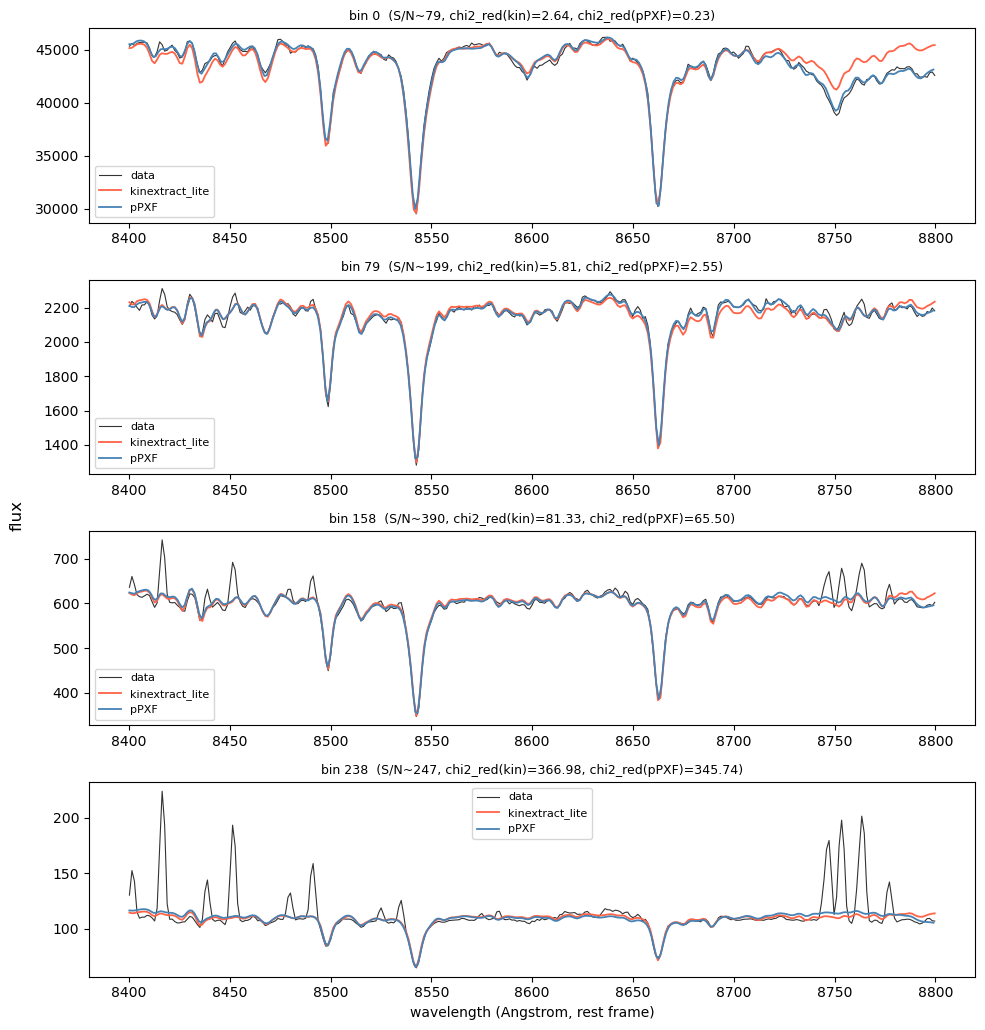

In [25]:
example_bins = np.unique(np.linspace(0, nbins - 1, min(4, nbins)).astype(int))

fig, axes = plt.subplots(len(example_bins), 1, figsize=(10, 2.6 * len(example_bins)), sharex=False)
axes = np.atleast_1d(axes)
for ax, j in zip(axes, example_bins):
    kin = kin_results[j]
    pp = ppxf_results[j]
    ax.plot(wave_fit, bin_spectra[:, j], color='black', lw=0.8, alpha=0.8, label='data')
    ax.plot(wave_fit, kin['model'], color='tomato', lw=1.3, label='kinextract')
    ax.plot(lam_gal_log, pp.bestfit, color='steelblue', lw=1.3, label='pPXF')
    ax.set_title(f"bin {j}  (S/N~{bin_sn[j]:.0f}, chi2_red(kin)={kin['chi2_red']:.2f}, chi2_red(pPXF)={pp.chi2:.2f})",
                 fontsize=9)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('wavelength (Angstrom, rest frame)')
fig.supylabel('flux')
plt.tight_layout(); plt.show()


## 8. Extracted LOSVDs -- same example bins

pPXF only returns Gauss-Hermite moments (V, sigma, h3, h4), not a curve --
its LOSVD is reconstructed here via `gauss_hermite_model` on the same
velocity grid `kinextract` used for that bin, so the two curves are
directly comparable.

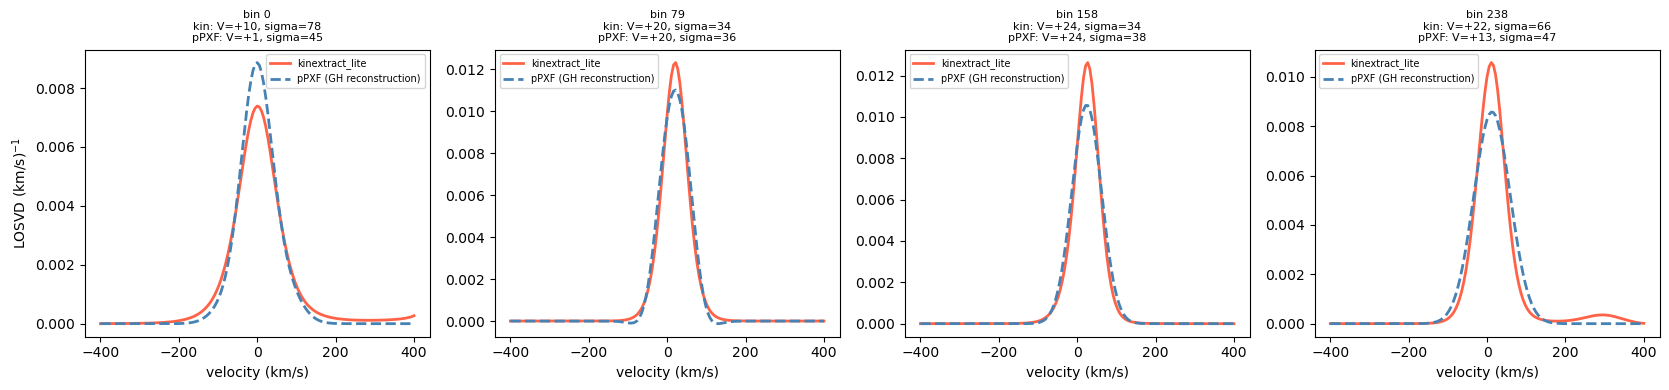

In [26]:
fig, axes = plt.subplots(1, len(example_bins), figsize=(4.2 * len(example_bins), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, j in zip(axes, example_bins):
    kin = kin_results[j]
    pp = ppxf_results[j]

    v_grid = kin['v_grid']
    b_kin = kin['b'] / np.trapezoid(np.maximum(kin['b'], 0.0), v_grid)
    b_pp = gauss_hermite_model(v_grid, 1.0, pp.sol[0], pp.sol[1], pp.sol[2], pp.sol[3])
    b_pp = b_pp / np.trapezoid(b_pp, v_grid)

    ax.plot(v_grid, b_kin, color='tomato', lw=2.0, label='kinextract')
    ax.plot(v_grid, b_pp, color='steelblue', lw=2.0, ls='--', label='pPXF (GH reconstruction)')
    ax.set_title(f"bin {j}\nkin: V={kin['moments']['vherm']:+.0f}, sigma={kin['moments']['sherm']:.0f}\n"
                 f"pPXF: V={pp.sol[0]:+.0f}, sigma={pp.sol[1]:.0f}", fontsize=8)
    ax.set_xlabel('velocity (km/s)')
    ax.legend(fontsize=7)
axes[0].set_ylabel(r'LOSVD (km/s)$^{-1}$')
plt.tight_layout(); plt.show()


## 9. Moment maps -- kinextract, pPXF, and their residual

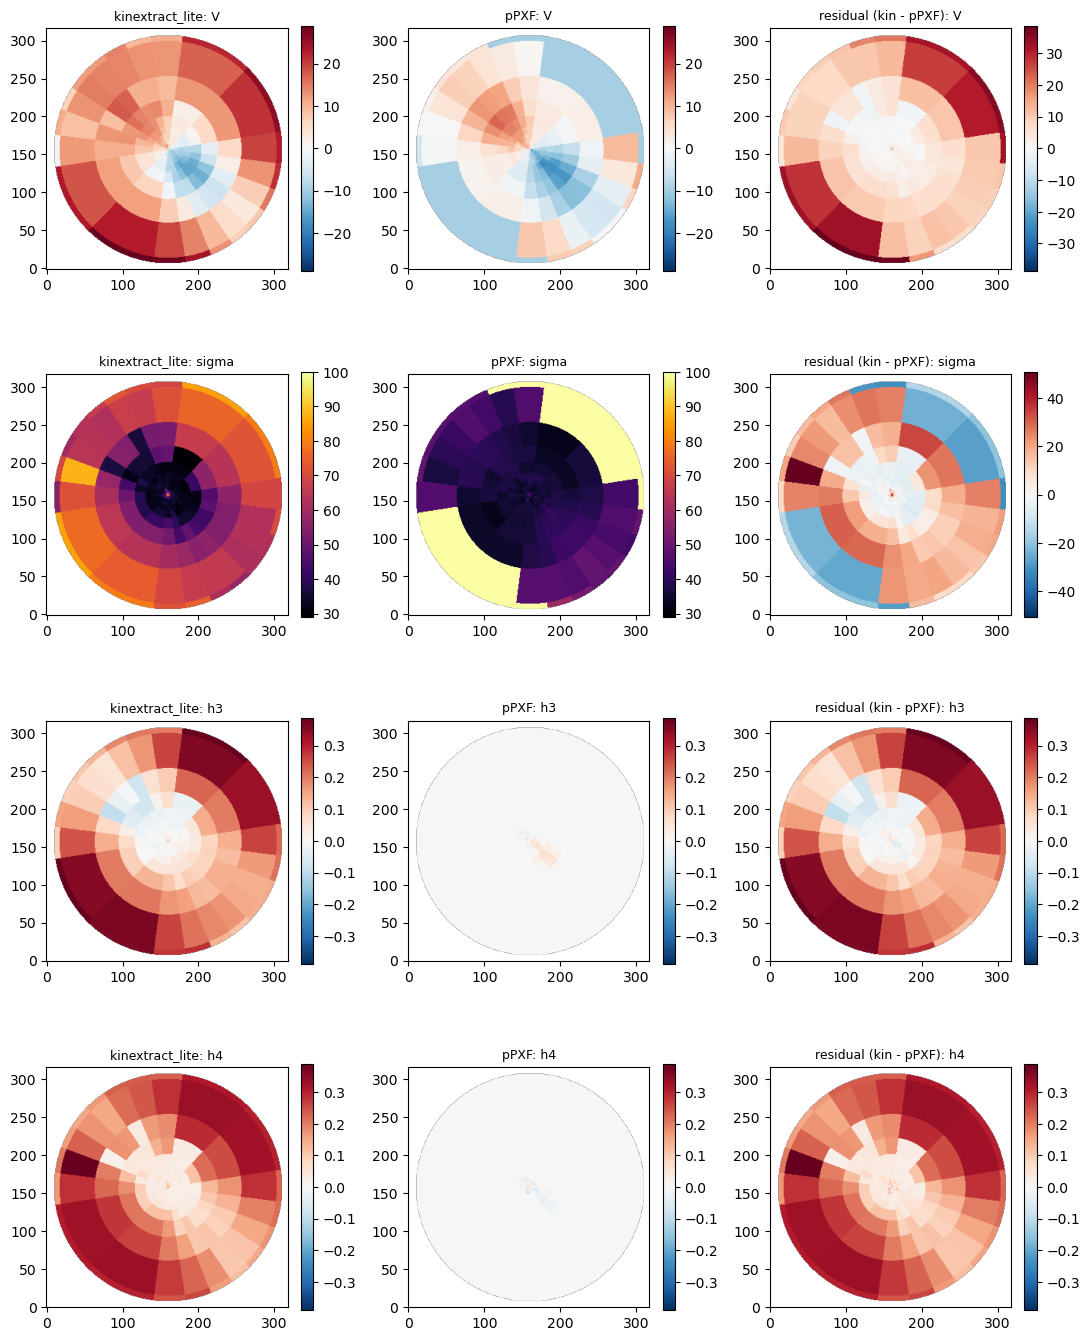

In [27]:
AXIS_DEG = PA_DEG          # use kinematic major axis; or set manually, e.g. 135.77
AXIS_HALF_WIDTH_DEG = 12   # angular wedge half-width around axis
USE_WEDGE = True           # True = angular wedge, False = fixed-width slit
SLIT_HALF_WIDTH_ARCSEC = 0.5

# Use binning center if available; otherwise fall back to brightest good spaxel
try:
    cx, cy = center_x_arcsec, center_y_arcsec
except NameError:
    valid_signal = np.where(good, signal_map, np.nan)
    brightest_j, brightest_i = np.unravel_index(np.nanargmax(valid_signal), valid_signal.shape)
    cx, cy = x_arcsec[brightest_j, brightest_i], y_arcsec[brightest_j, brightest_i]

theta = np.deg2rad(AXIS_DEG)
ux, uy = np.cos(theta), np.sin(theta)

dx = x_gen - cx
dy = y_gen - cy

# signed radius along chosen axis
r_signed = dx * ux + dy * uy

kin_V = np.array([r['moments']['vherm'] for r in kin_results])

kin_sigma = np.array([r['moments']['sherm'] for r in kin_results])
kin_h3 = np.array([r['moments']['h3'] for r in kin_results])
kin_h4 = np.array([r['moments']['h4'] for r in kin_results])

ppxf_V = np.array([r.sol[0] for r in ppxf_results])
ppxf_sigma = np.array([r.sol[1] for r in ppxf_results])
ppxf_h3 = np.array([r.sol[2] for r in ppxf_results])
ppxf_h4 = np.array([r.sol[3] for r in ppxf_results])


V_offset = np.mean([np.nanmedian(kin_V[(r_signed < 10.0) & (r_signed > -10.0)]), np.nanmedian(ppxf_V[(r_signed < 10.0) & (r_signed > -10.0)])])
kin_V -= V_offset
ppxf_V -= V_offset

def paint_map(bin_map, values):
    out = np.full(bin_map.shape, np.nan)
    for j, v in enumerate(values):
        out[bin_map == j] = v
    return out


moment_names = ['V', 'sigma', 'h3', 'h4']
moment_ylabels = [
    r'$V$ [km s$^{-1}$]',
    r'$\sigma$ [km s$^{-1}$]',
    r'$h_3$',
    r'$h_4$'
]
kin_vals = [kin_V, kin_sigma, kin_h3, kin_h4]
ppxf_vals = [ppxf_V, ppxf_sigma, ppxf_h3, ppxf_h4]

fig, axes = plt.subplots(4, 3, figsize=(11, 14))
col_titles = ['kinextract', 'pPXF', 'residual (kin - pPXF)']
for i, name in enumerate(moment_names):
    kmap = paint_map(bin_map, kin_vals[i])
    pmap = paint_map(bin_map, ppxf_vals[i])
    rmap = kmap - pmap

    if name == 'sigma':
        cmap, vmin, vmax = 'inferno', np.nanmin([kmap, pmap]), np.nanmax([kmap, pmap])
    else:
        cmap = 'RdBu_r'
        vmax = np.nanmax(np.abs([kmap, pmap]))
        vmin = -vmax

    for col, (m, label) in enumerate(zip([kmap, pmap, rmap], col_titles)):
        ax = axes[i, col]
        if col < 2:
            im = ax.imshow(m, origin='lower', cmap=cmap, vmin=vmin, vmax=vmax)
        else:
            rmax = np.nanmax(np.abs(rmap)) if np.isfinite(rmap).any() else 1.0
            im = ax.imshow(m, origin='lower', cmap='RdBu_r', vmin=-rmax, vmax=rmax)
        ax.set_title(f"{label}: {name}", fontsize=9)
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()


47 bins selected along axis PA=135.77 deg
47 bins selected after fit-quality cuts


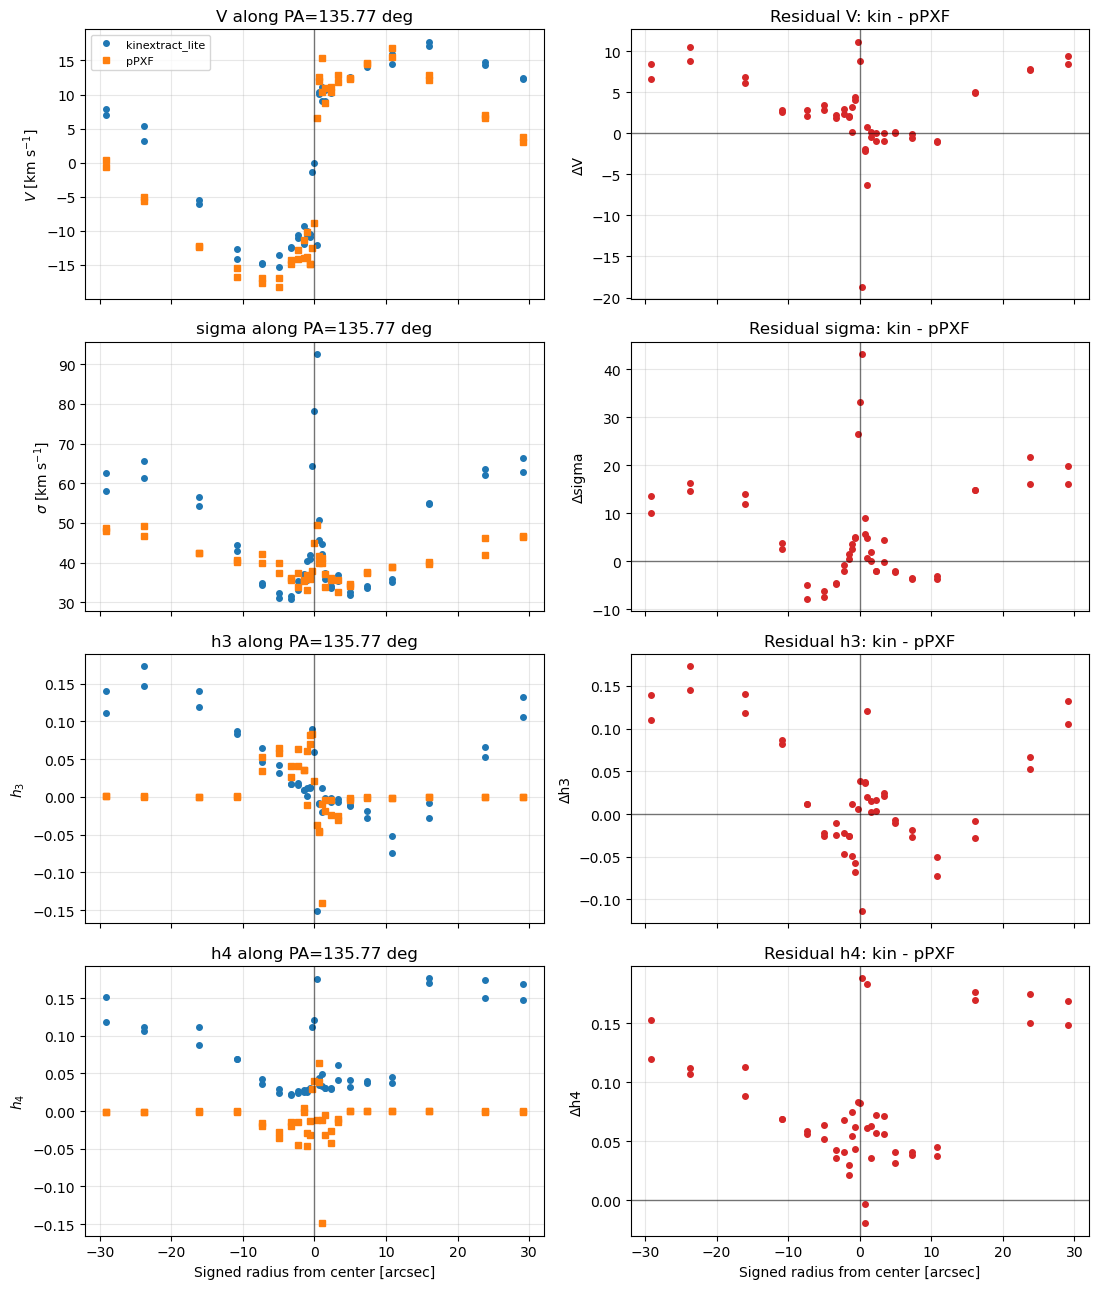

In [28]:
# ------------------------------------------------------------
# Plot moments along a chosen axis
# ------------------------------------------------------------

# perpendicular distance from chosen axis
d_perp = -dx * uy + dy * ux

# angle of each bin relative to the chosen axis, folded across +/- axis
phi = np.arctan2(dy, dx)
dphi = np.arctan2(np.sin(phi - theta), np.cos(phi - theta))
dphi_folded = np.minimum(np.abs(dphi), np.abs(np.pi - np.abs(dphi)))

if USE_WEDGE:
    axis_mask = dphi_folded <= np.deg2rad(AXIS_HALF_WIDTH_DEG)
else:
    axis_mask = np.abs(d_perp) <= SLIT_HALF_WIDTH_ARCSEC

# Always keep the central bin if present
axis_mask |= np.hypot(dx, dy) == np.nanmin(np.hypot(dx, dy))

if len(r_signed) != len(kin_V):
    raise ValueError(f"len(r_signed)={len(r_signed)} but len(kin_V)={len(kin_V)}")

# Fit-quality masks
fit_mask = (
    np.isfinite(r_signed)
    & axis_mask
    # & (ppxf_V != 0.0)
    # & (ppxf_sigma != 100.0)
    # & (kin_h4 < 0.05)
    # & (r_signed < 10.0)
    # & (r_signed > -10.0)
)

print(f"{axis_mask.sum()} bins selected along axis PA={AXIS_DEG:.2f} deg")
print(f"{fit_mask.sum()} bins selected after fit-quality cuts")

fig, axes = plt.subplots(4, 2, figsize=(11, 13), sharex=True)

for i, name in enumerate(moment_names):
    kin_mom = np.asarray(kin_vals[i])
    ppxf_mom = np.asarray(ppxf_vals[i])
    resid_mom = kin_mom - ppxf_mom

    m = fit_mask & np.isfinite(kin_mom) & np.isfinite(ppxf_mom)
    order = np.argsort(r_signed[m])

    rr = r_signed[m][order]
    kk = kin_mom[m][order]
    pp = ppxf_mom[m][order]
    dd = resid_mom[m][order]

    ax = axes[i, 0]
    ax.plot(rr, kk, 'o', ms=4, color='tab:blue', label='kinextract')
    ax.plot(rr, pp, 's', ms=4, color='tab:orange', label='pPXF')
    ax.axvline(0, color='k', lw=1, alpha=0.5)
    ax.grid(alpha=0.3)
    ax.set_ylabel(moment_ylabels[i])
    ax.set_title(f'{name} along PA={AXIS_DEG:.2f} deg')
    if i == 0:
        ax.legend(fontsize=8)

    axr = axes[i, 1]
    axr.plot(rr, dd, 'o', ms=4, color='tab:red')
    axr.axvline(0, color='k', lw=1, alpha=0.5)
    axr.axhline(0, color='k', lw=1, alpha=0.5)
    axr.grid(alpha=0.3)
    axr.set_ylabel(f'Δ{name}')
    axr.set_title(f'Residual {name}: kin - pPXF')

axes[-1, 0].set_xlabel('Signed radius from center [arcsec]')
axes[-1, 1].set_xlabel('Signed radius from center [arcsec]')

plt.tight_layout()
plt.show()

In [ ]:
V_offset = np.nanmedian(kin_V[(r_signed < 10.0) & (r_signed > -10.0)])
V_offset_ppxf = np.nanmedian(ppxf_V[(r_signed < 10.0) & (r_signed > -10.0)])
print(f"median V offset (kinextract) = {V_offset:.2f} km/s, median V offset (pPXF) = {V_offset_ppxf:.2f} km/s")

median V offset (kinextract) = 0.00 km/s, median V offset (pPXF) = -3.52 km/s


## Notes / current limitations

- This is a **temporary testing notebook** built to sanity-check
  `kinextract` against pPXF on identical dartboard bins, not a validated
  head-to-head benchmark -- see `dev_notes/` for the project's actual
  validation history.
- The pPXF fit here is a single-pass `moments=4` call with no iterative
  sigma-clipping/outlier-masking stage, unlike the more careful
  `ppxf_fit_and_clean` wrapper used in the `pPXF_N5102.ipynb` reference
  notebook -- a deliberate simplification, not a claim of best-practice pPXF.
- For the synthetic cube, ground truth (`cube.truth`) is spatially constant
  (same V/sigma/h3/h4 at every spaxel) -- residual-map scatter there reflects
  per-bin noise and method differences, not a true spatial kinematic
  structure either method should be expected to recover.
- For the real cube, NGC 5102's systemic velocity is hardcoded above
  (~468 km/s from NED) since it is not present in this FITS file's header --
  double check against a current literature value before trusting absolute
  `V` maps.
- Runtime is dominated by `kinextract`'s per-bin two-stage fit
  (~5-10s/bin after JAX's one-time JIT warmup); expect several minutes total
  for the full 50x50 synthetic cube, and potentially much longer on the real
  cube depending on `RMAX_ARCSEC`/`N_THETA_PER_QUADRANT` (see Section 3's
  printed bin count and runtime estimate before running Sections 5-6).
  `USE_CACHE=True` (Section 1) skips both fit loops entirely on a rerun with
  the same `DATA_MODE`/`PA_DEG`/`RMAX_ARCSEC`/`N_THETA_PER_QUADRANT`/`nbins`,
  loading pickled results from `cache/` instead -- delete the relevant
  `cache/kin_*.pkl`/`cache/ppxf_*.pkl` file (or set `USE_CACHE=False`) to
  force a fresh run.